# LRU Baseline Analysis (100k Window)

## Libraries

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

## Workload Data

In [14]:
chirper = pd.read_csv("../data/chirper_LRU_100k.csv")
mcf = pd.read_csv("../data/mcf_LRU_100k.csv")
omnetpp = pd.read_csv("../data/omnetpp_LRU_100k.csv")
tomcat = pd.read_csv("../data/tomcat_LRU_100k.csv")
tpcc = pd.read_csv("../data/tpcc_LRU_100k.csv")

## Class-wise Hits and Misses

In [15]:
totals = pd.DataFrame(
    [chirper.sum(), mcf.sum(), omnetpp.sum(), tomcat.sum(), tpcc.sum()],
    index=["Chirper", "MCF", "OMNeT++", "Tomcat", "TPC-C"]
)

totals = totals[[
    "instruction_hits", "instruction_misses",
    "data_hits", "data_misses",
    "pte_hits", "pte_misses"
]]

totals

,instruction_hits,instruction_misses,data_hits,data_misses,pte_hits,pte_misses
Chirper,146676.0,57703.0,173379.0,71862.0,21678.0,7626.0
MCF,0.0,0.0,333183.0,260040.0,256058.0,642.0
OMNeT++,5849.0,315.0,157041.0,115291.0,52629.0,17248.0
Tomcat,126857.0,48608.0,116897.0,49443.0,12002.0,4488.0
TPC-C,479647.0,8130.0,336678.0,14252.0,3212.0,365.0


## L2 Access Mix

In [16]:
accesses = pd.DataFrame()

accesses["Instruction"] = totals["instruction_hits"] + totals["instruction_misses"]
accesses["Data"] = totals["data_hits"] + totals["data_misses"]
accesses["PTE"] = totals["pte_hits"] + totals["pte_misses"]

percentages = accesses.div(accesses.sum(axis=1), axis=0) * 100
percentages.round(2)

,Instruction,Data,PTE
Chirper,42.67,51.21,6.12
MCF,0.00,69.80,30.20
OMNeT++,1.77,78.17,20.06
Tomcat,48.97,46.43,4.60
TPC-C,57.91,41.66,0.42


## L2 Access Mix by Workload

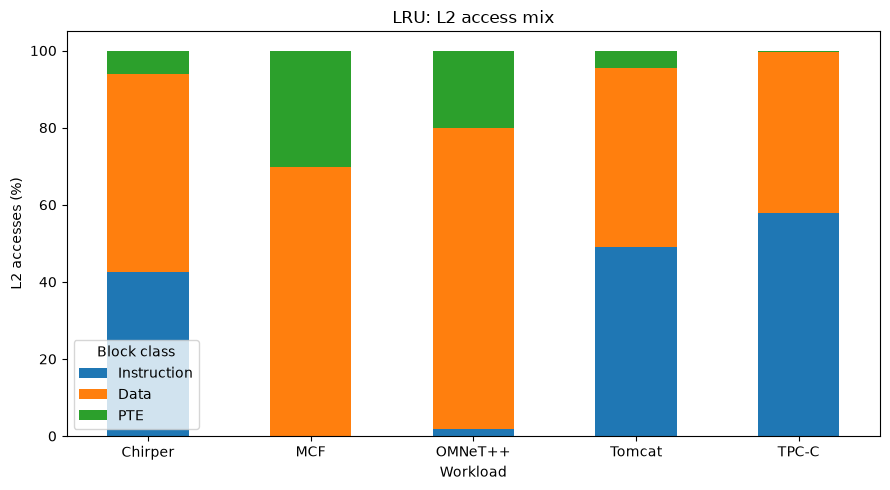

In [17]:
percentages.plot.bar(stacked=True, figsize=(9, 5))

plt.title("LRU: L2 access mix")
plt.xlabel("Workload")
plt.ylabel("L2 accesses (%)")
plt.xticks(rotation=0)
plt.legend(title="Block class")
plt.tight_layout()

plt.savefig("../results/baseline_class_mix.png", dpi=300)
plt.show()

## Class-wise Miss Rates

In [18]:
miss_rates = pd.DataFrame()

miss_rates["Instruction"] = totals["instruction_misses"] / accesses["Instruction"] * 100
miss_rates["Data"] = totals["data_misses"] / accesses["Data"] * 100
miss_rates["PTE"] = totals["pte_misses"] / accesses["PTE"] * 100

miss_rates.round(2)

,Instruction,Data,PTE
Chirper,28.23,29.30,26.02
MCF,NaN,43.84,0.25
OMNeT++,5.11,42.33,24.68
Tomcat,27.70,29.72,27.22
TPC-C,1.67,4.06,10.20


## Miss Rates by Workload

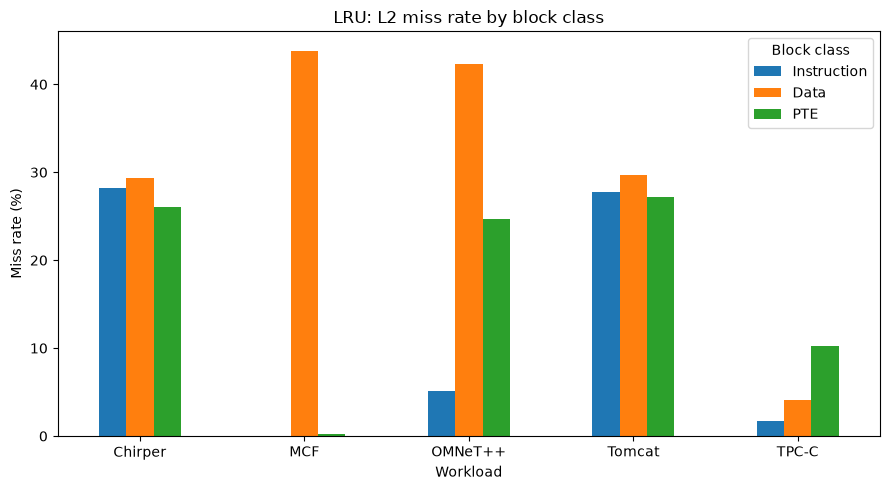

In [19]:
miss_rates.plot.bar(figsize=(9, 5))

plt.title("LRU: L2 miss rate by block class")
plt.xlabel("Workload")
plt.ylabel("Miss rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Block class")
plt.tight_layout()

plt.savefig("../results/baseline_miss_rates.png", dpi=300)
plt.show()

## Overall IPC

In [20]:
ipc = pd.Series({
    "Chirper": chirper["instructions"].sum() / chirper["cycles"].sum(),
    "MCF": mcf["instructions"].sum() / mcf["cycles"].sum(),
    "OMNeT++": omnetpp["instructions"].sum() / omnetpp["cycles"].sum(),
    "Tomcat": tomcat["instructions"].sum() / tomcat["cycles"].sum(),
    "TPC-C": tpcc["instructions"].sum() / tpcc["cycles"].sum()
}, name="IPC")

ipc

Chirper    0.300000
MCF        0.323275
OMNeT++    0.216998
Tomcat     0.369342
TPC-C      0.407450
Name: IPC, dtype: float64

## Overall IPC by Workload

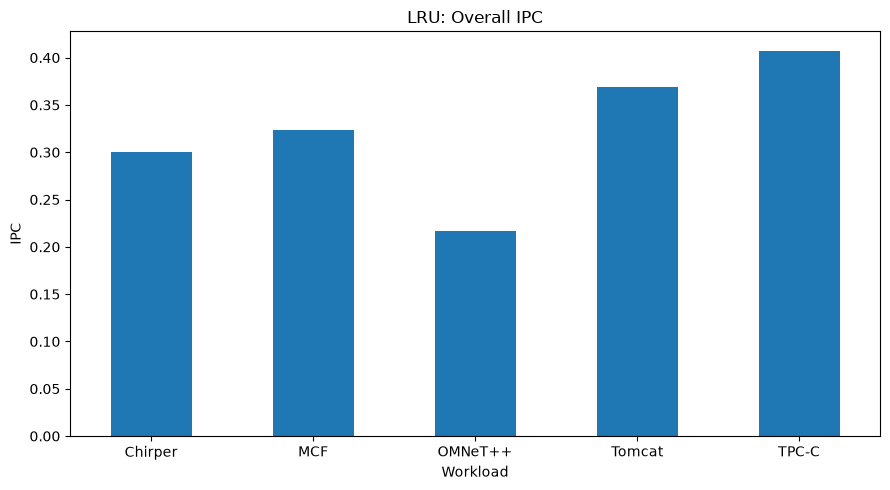

In [21]:
ipc.plot.bar(figsize=(9, 5))

plt.title("LRU: Overall IPC")
plt.xlabel("Workload")
plt.ylabel("IPC")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../results/baseline_ipc.png", dpi=300)
plt.show()

## Phase-wise IPC

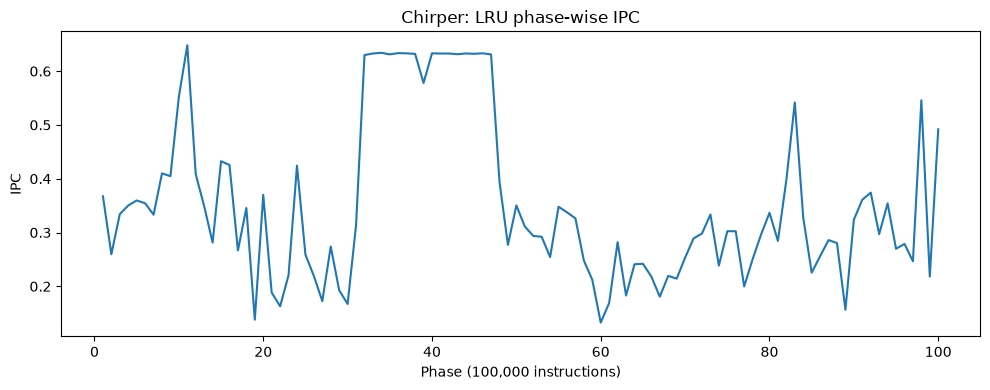

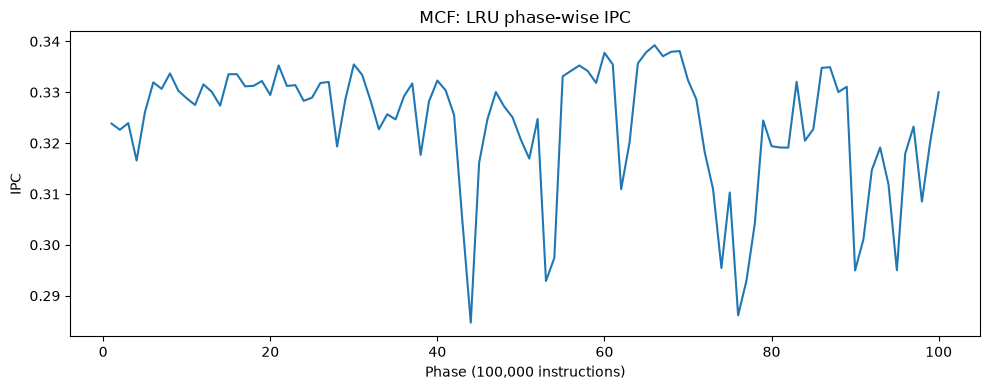

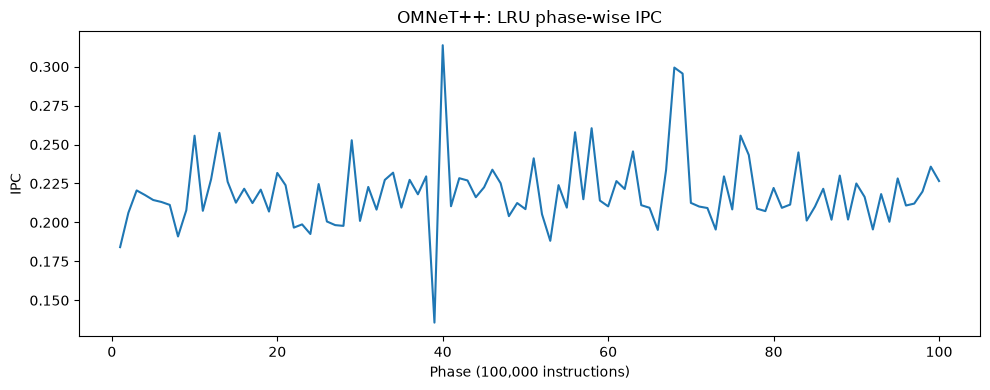

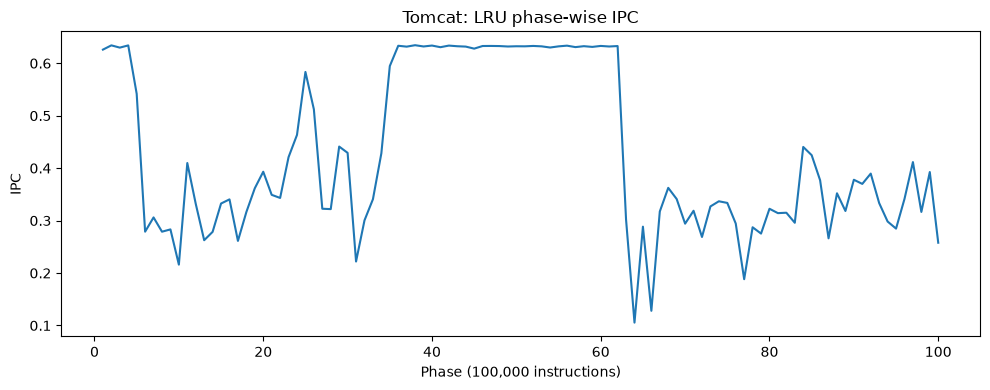

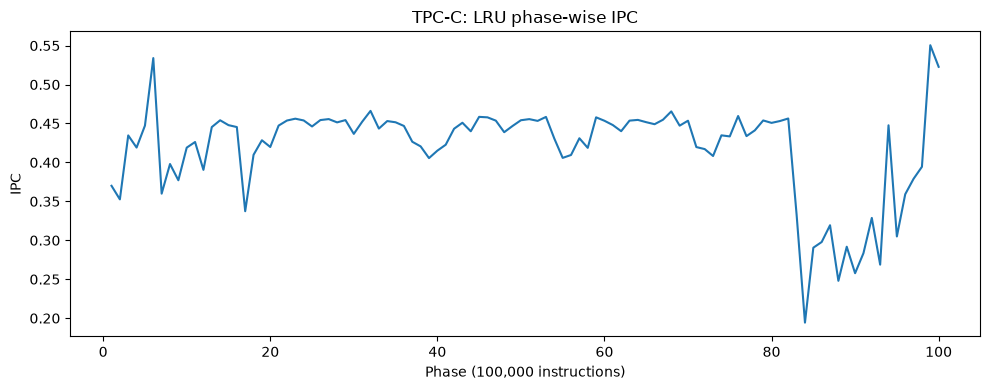

In [22]:
for name, data in [
    ("Chirper", chirper),
    ("MCF", mcf),
    ("OMNeT++", omnetpp),
    ("Tomcat", tomcat),
    ("TPC-C", tpcc)
]:
    plt.figure(figsize=(10, 4))
    plt.plot(data["phase"], data["ipc"])

    plt.title(f"{name}: LRU phase-wise IPC")
    plt.xlabel("Phase (100,000 instructions)")
    plt.ylabel("IPC")
    plt.tight_layout()

    plt.savefig(f"../results/{name}_baseline_phase_ipc.png", dpi=300)
    plt.show()

## Phase-wise L2 Access Mix

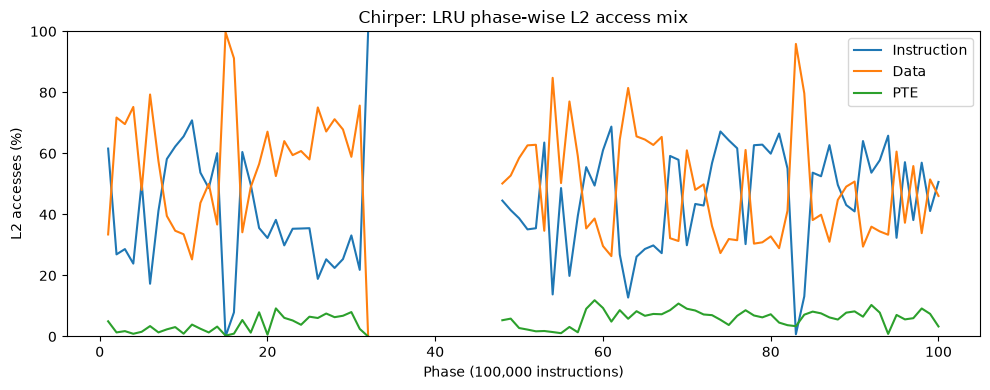

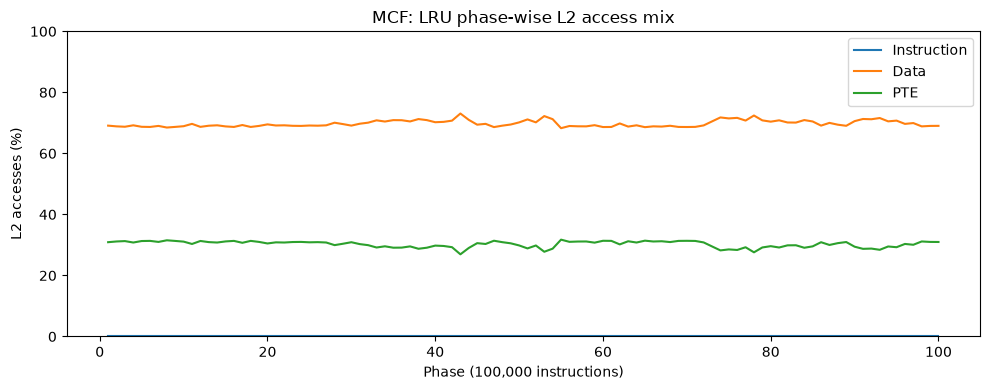

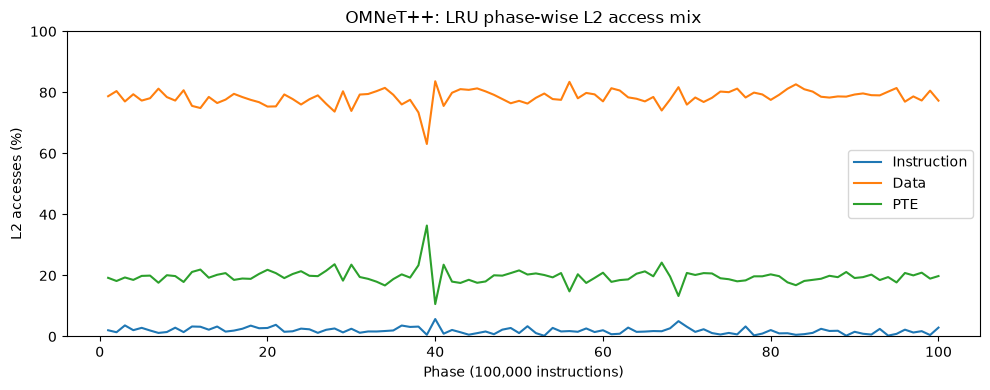

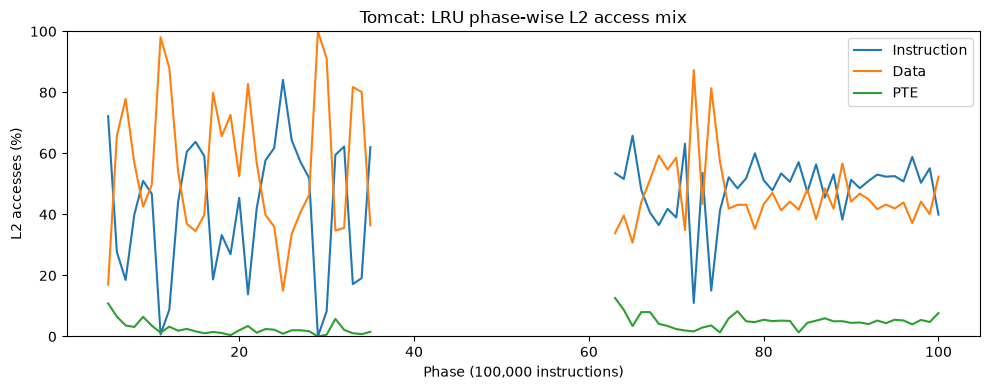

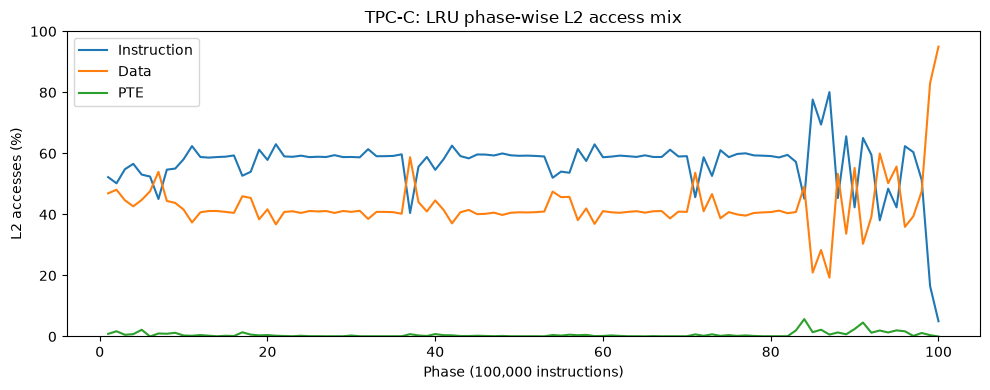

In [23]:
for name, data in [
    ("Chirper", chirper),
    ("MCF", mcf),
    ("OMNeT++", omnetpp),
    ("Tomcat", tomcat),
    ("TPC-C", tpcc)
]:
    instruction = data["instruction_hits"] + data["instruction_misses"]
    demand_data = data["data_hits"] + data["data_misses"]
    pte = data["pte_hits"] + data["pte_misses"]
    total = instruction + demand_data + pte

    plt.figure(figsize=(10, 4))

    plt.plot(data["phase"], instruction / total * 100, label="Instruction")
    plt.plot(data["phase"], demand_data / total * 100, label="Data")
    plt.plot(data["phase"], pte / total * 100, label="PTE")

    plt.title(f"{name}: LRU phase-wise L2 access mix")
    plt.xlabel("Phase (100,000 instructions)")
    plt.ylabel("L2 accesses (%)")
    plt.ylim(0, 100)
    plt.legend()
    plt.tight_layout()

    plt.savefig(f"../results/{name}_baseline_phase_mix.png", dpi=300)
    plt.show()

## Phase-wise L2 Misses

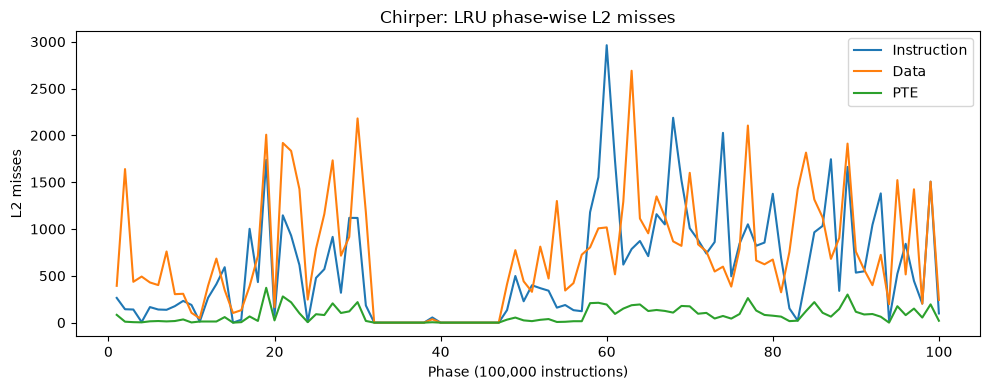

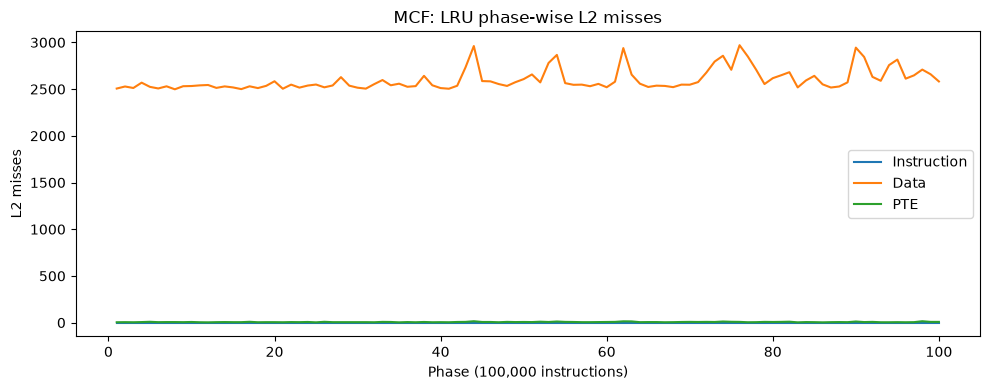

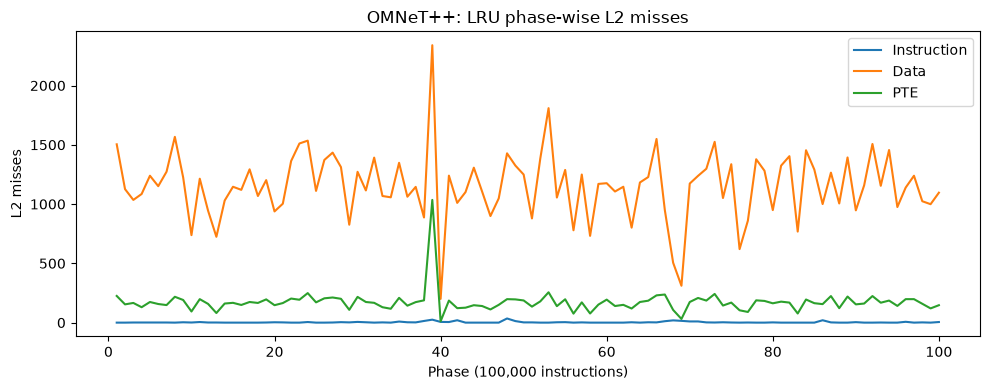

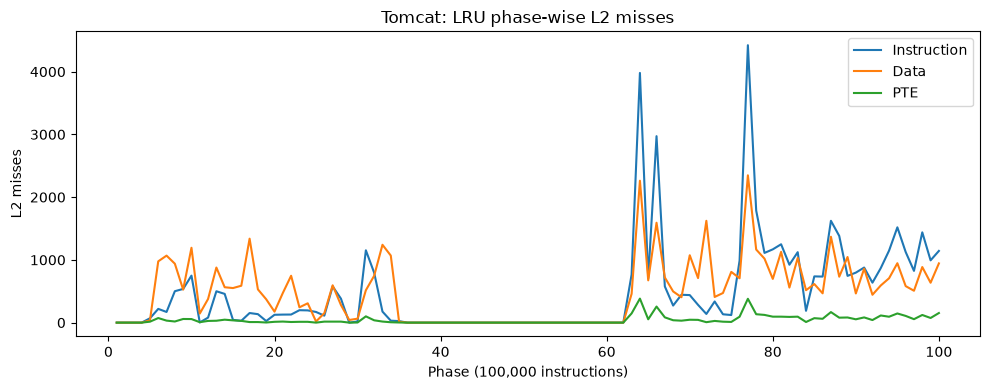

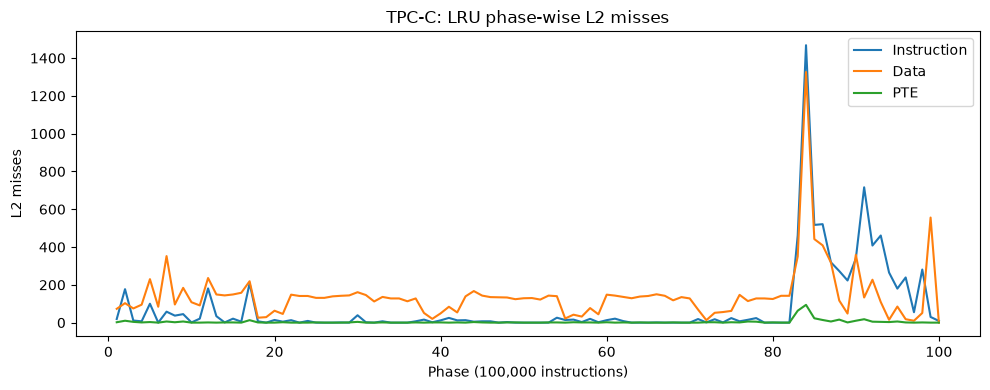

In [24]:
for name, data in [
    ("Chirper", chirper),
    ("MCF", mcf),
    ("OMNeT++", omnetpp),
    ("Tomcat", tomcat),
    ("TPC-C", tpcc)
]:
    plt.figure(figsize=(10, 4))

    plt.plot(data["phase"], data["instruction_misses"], label="Instruction")
    plt.plot(data["phase"], data["data_misses"], label="Data")
    plt.plot(data["phase"], data["pte_misses"], label="PTE")

    plt.title(f"{name}: LRU phase-wise L2 misses")
    plt.xlabel("Phase (100,000 instructions)")
    plt.ylabel("L2 misses")
    plt.legend()
    plt.tight_layout()

    plt.savefig(f"../results/{name}_baseline_phase_misses.png", dpi=300)
    plt.show()